In [ ]:
%pip install pillow pymupdf pandas matplotlib

In [2]:
# TagRivo - Digital Metadata Privacy Auditor
# Module 1: Project Initialization

from pathlib import Path
from PIL import Image, ExifTags, PngImagePlugin
import pymupdf
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(r"D:\Projects\TagRivo")

SAMPLES_DIR = PROJECT_ROOT / "samples"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
SANITIZED_DIR = OUTPUT_DIR / "sanitized"
REPORTS_DIR = OUTPUT_DIR / "reports"

# Create folders if they do not exist
for folder in [
    SAMPLES_DIR,
    SANITIZED_DIR,
    REPORTS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("TagRivo initialized successfully!")
print("Project root:", PROJECT_ROOT)
print("Sample directory:", SAMPLES_DIR)
print("Output directory:", OUTPUT_DIR)

TagRivo initialized successfully!
Project root: D:\Projects\TagRivo
Sample directory: D:\Projects\TagRivo\samples
Output directory: D:\Projects\TagRivo\outputs


In [3]:
# Module 2: Synthetic Test File Generator

def create_test_files():

    # Synthetic JPEG with EXIF metadata
    image_path = SAMPLES_DIR / "demo_image.jpg"

    if not image_path.exists():
        image = Image.new(
            "RGB",
            (500, 300),
            color=(90, 145, 200)
        )

        exif = Image.Exif()
        exif[271] = "Synthetic Device Manufacturer"
        exif[272] = "TagRivo Test Camera"
        exif[315] = "Demo Author"

        image.save(image_path, exif=exif)

    # Synthetic PNG with text metadata
    png_path = SAMPLES_DIR / "demo_image.png"

    if not png_path.exists():
        image = Image.new(
            "RGB",
            (500, 300),
            color=(120, 180, 140)
        )

        metadata = PngImagePlugin.PngInfo()
        metadata.add_text("Author", "Demo Author")
        metadata.add_text("Software", "Test Image Editor")

        image.save(png_path, pnginfo=metadata)

    # Synthetic PDF with document metadata
    pdf_path = SAMPLES_DIR / "demo_document.pdf"

    if not pdf_path.exists():
        document = pymupdf.open()

        page = document.new_page()
        page.insert_text(
            (72, 100),
            "TagRivo Synthetic PDF Test"
        )

        document.set_metadata({
            "title": "Test Document",
            "author": "Demo Author",
            "creator": "TagRivo Test Generator"
        })

        document.save(pdf_path)
        document.close()

    print("Synthetic test files are ready!")

    for file in SAMPLES_DIR.iterdir():
        if file.is_file():
            print(file.name)


create_test_files()

Synthetic test files are ready!
demo_document.pdf
demo_image.jpg
demo_image.png


In [4]:
# Module 3: Basic Metadata Extraction Engine

def extract_metadata(file_path):

    file_path = Path(file_path)

    if not file_path.exists():
        return {"error": "File not found"}

    metadata = {}

    try:
        extension = file_path.suffix.lower()

        if extension in [".jpg", ".jpeg", ".png"]:

            with Image.open(file_path) as image:

                metadata["File Type"] = image.format
                metadata["Dimensions"] = str(image.size)

                exif_data = image.getexif()

                for tag_id, value in exif_data.items():
                    tag_name = ExifTags.TAGS.get(
                        tag_id,
                        str(tag_id)
                    )
                    metadata[tag_name] = str(value)

                if image.format == "PNG":
                    for key, value in image.info.items():
                        metadata[key] = str(value)

        elif extension == ".pdf":

            with pymupdf.open(file_path) as document:
                metadata = {
                    key: str(value)
                    for key, value in document.metadata.items()
                    if value is not None
                }

        else:
            return {"error": "Unsupported file type"}

    except Exception as error:
        return {"error": str(error)}

    return metadata


# Test metadata extraction
sample_file = SAMPLES_DIR / "demo_image.jpg"

result = extract_metadata(sample_file)

print("Metadata Inspection Results")
print("---------------------------")

for key, value in result.items():
    print(f"{key}: {value}")

Metadata Inspection Results
---------------------------
File Type: JPEG
Dimensions: (500, 300)
Model: TagRivo Test Camera
Artist: Demo Author
Make: Synthetic Device Manufacturer


In [6]:
# TagRivo - Module 4
# Privacy Risk Detection and Classification

RISK_RULES = {
    "Location Exposure": {
        "fields": [
            "GPSInfo", "GPSLatitude", "GPSLongitude",
            "GPSLatitudeRef", "GPSLongitudeRef"
        ],
        "points": 45,
        "explanation": "Location metadata may reveal where a file was captured."
    },

    "Identity Exposure": {
        "fields": ["Author", "Artist", "Owner"],
        "points": 25,
        "explanation": "Authorship information may disclose a person's identity."
    },

    "Device Fingerprinting": {
        "fields": [
            "Make", "Model", "SerialNumber",
            "BodySerialNumber", "CameraSerialNumber"
        ],
        "points": 20,
        "explanation": "Device information may help identify or correlate devices."
    },

    "Timeline Exposure": {
        "fields": [
            "DateTime", "DateTimeOriginal",
            "DateTimeDigitized", "creationDate",
            "modDate"
        ],
        "points": 10,
        "explanation": "Timestamps may reveal information about user activity."
    },

    "Software Disclosure": {
        "fields": ["Software", "Creator", "Producer"],
        "points": 10,
        "explanation": "Software metadata may reveal tools used to create the file."
    },

    "Document Information": {
        "fields": ["Title", "Subject", "Keywords"],
        "points": 5,
        "explanation": "Document metadata may disclose contextual information."
    }
}


def normalize_field_name(field_name):
    return "".join(
        char.lower()
        for char in str(field_name)
        if char.isalnum()
    )


def calculate_privacy_risk(metadata):

    findings = []
    total_score = 0

    available_fields = {}

    for field, value in metadata.items():

        if value is None or str(value).strip() == "":
            continue

        normalized = normalize_field_name(field)
        available_fields[normalized] = field

    for category, rule in RISK_RULES.items():

        matched_fields = []

        for expected_field in rule["fields"]:

            normalized = normalize_field_name(expected_field)

            if normalized in available_fields:
                matched_fields.append(
                    available_fields[normalized]
                )

        if matched_fields:

            findings.append({
                "category": category,
                "detected_fields": matched_fields,
                "points": rule["points"],
                "explanation": rule["explanation"]
            })

            total_score += rule["points"]

    total_score = min(total_score, 100)

    if total_score == 0:
        risk_level = "No Detected Risk"

    elif total_score < 15:
        risk_level = "Low"

    elif total_score < 40:
        risk_level = "Moderate"

    elif total_score < 70:
        risk_level = "High"

    else:
        risk_level = "Critical"

    return {
        "risk_score": total_score,
        "risk_level": risk_level,
        "findings": findings
    }


print("TagRivo Privacy Risk Engine initialized!")

TagRivo Privacy Risk Engine initialized!


In [7]:
# TagRivo - Module 5
# File Privacy Audit

def audit_file(file_path):

    file_path = Path(file_path)

    metadata = extract_metadata(file_path)

    if "error" in metadata:
        return {
            "file": file_path.name,
            "status": "Failed",
            "error": metadata["error"]
        }

    # Additional check for GPS EXIF structure
    if file_path.suffix.lower() in [".jpg", ".jpeg"]:

        try:
            with Image.open(file_path) as image:
                exif = image.getexif()

                gps_data = exif.get_ifd(34853)

                if gps_data:
                    metadata["GPSInfo"] = (
                        "GPS metadata structure detected"
                    )

        except (OSError, ValueError, TypeError) as error:
            return {
                "file": file_path.name,
                "status": "Failed",
                "error": f"EXIF inspection failed: {error}"
            }

    risk_result = calculate_privacy_risk(metadata)

    return {
        "file": file_path.name,
        "status": "Success",
        "metadata": metadata,
        "risk_score": risk_result["risk_score"],
        "risk_level": risk_result["risk_level"],
        "findings": risk_result["findings"]
    }


print("TagRivo File Audit Module is ready!")

TagRivo File Audit Module is ready!


In [8]:
# TagRivo - Module 6
# Privacy Audit Demonstration

test_files = [
    "demo_image.jpg",
    "demo_image.png",
    "demo_document.pdf"
]

for filename in test_files:

    file_path = SAMPLES_DIR / filename

    result = audit_file(file_path)

    print("\n" + "=" * 50)
    print("FILE:", filename)
    print("=" * 50)

    if result["status"] == "Success":

        print("Risk Score:", result["risk_score"], "/ 100")
        print("Risk Level:", result["risk_level"])

        print("\nDetected Privacy Risks:")

        if not result["findings"]:
            print("No supported privacy risk fields detected.")

        for finding in result["findings"]:

            print("\nCategory:", finding["category"])
            print("Fields:", ", ".join(finding["detected_fields"]))
            print("Points:", finding["points"])
            print("Reason:", finding["explanation"])

    else:
        print("Scan failed:", result["error"])


FILE: demo_image.jpg
Risk Score: 45 / 100
Risk Level: High

Detected Privacy Risks:

Category: Identity Exposure
Fields: Artist
Points: 25
Reason: Authorship information may disclose a person's identity.

Category: Device Fingerprinting
Fields: Make, Model
Points: 20
Reason: Device information may help identify or correlate devices.

FILE: demo_image.png
Risk Score: 35 / 100
Risk Level: Moderate

Detected Privacy Risks:

Category: Identity Exposure
Fields: Author
Points: 25
Reason: Authorship information may disclose a person's identity.

Category: Software Disclosure
Fields: Software
Points: 10
Reason: Software metadata may reveal tools used to create the file.

FILE: demo_document.pdf
Risk Score: 40 / 100
Risk Level: High

Detected Privacy Risks:

Category: Identity Exposure
Fields: author
Points: 25
Reason: Authorship information may disclose a person's identity.

Category: Software Disclosure
Fields: creator
Points: 10
Reason: Software metadata may reveal tools used to create the 

In [9]:
# TagRivo - Module 7
# Initial Risk Engine Tests

# Test 1: No metadata
empty_result = calculate_privacy_risk({})
assert empty_result["risk_score"] == 0

# Test 2: Synthetic GPS field
gps_result = calculate_privacy_risk({
    "GPSInfo": "Synthetic GPS Data"
})
assert gps_result["risk_score"] == 45

# Test 3: Multiple identity fields
identity_result = calculate_privacy_risk({
    "Author": "Synthetic User",
    "Artist": "Synthetic User"
})
assert identity_result["risk_score"] == 25

# Test 4: Device + identity fields
combined_result = calculate_privacy_risk({
    "Make": "Test Manufacturer",
    "Model": "Test Camera",
    "Author": "Demo Author"
})
assert combined_result["risk_score"] == 45

# Test 5: Unsupported metadata field
unknown_result = calculate_privacy_risk({
    "UnknownField": "Test Value"
})
assert unknown_result["risk_score"] == 0

print("All 5 initial risk engine tests passed!")

All 5 initial risk engine tests passed!


In [10]:
# TagRivo - Module 8
# Cybersecurity Audit Summary

from IPython.display import display
import pandas as pd

audit_results = []
summary_records = []

for file_path in sorted(SAMPLES_DIR.iterdir()):

    if not file_path.is_file():
        continue

    if file_path.suffix.lower() not in [
        ".jpg", ".jpeg", ".png", ".pdf"
    ]:
        continue

    result = audit_file(file_path)

    audit_results.append(result)

    if result["status"] == "Success":

        summary_records.append({
            "File Name": result["file"],
            "Risk Score": result["risk_score"],
            "Risk Level": result["risk_level"],
            "Privacy Findings": len(result["findings"]),
            "Audit Status": "Completed"
        })

    else:

        summary_records.append({
            "File Name": result["file"],
            "Risk Score": None,
            "Risk Level": "Not Assessed",
            "Privacy Findings": 0,
            "Audit Status": "Failed"
        })


summary_df = pd.DataFrame(
    summary_records,
    columns=[
        "File Name",
        "Risk Score",
        "Risk Level",
        "Privacy Findings",
        "Audit Status"
    ]
)

print("=" * 60)
print("TAGRIVO | CYBERSECURITY AUDIT SUMMARY")
print("=" * 60)

display(summary_df)

TAGRIVO | CYBERSECURITY AUDIT SUMMARY


,File Name,Risk Score,Risk Level,Privacy Findings,Audit Status
0,demo_document.pdf,40,High,3,Completed
1,demo_image.jpg,45,High,2,Completed
2,demo_image.png,35,Moderate,2,Completed


In [11]:
# TagRivo - Module 9
# Detailed Privacy Findings Report

finding_records = []

for result in audit_results:

    if result["status"] != "Success":
        continue

    for finding in result["findings"]:

        finding_records.append({
            "File": result["file"],
            "Privacy Category": finding["category"],
            "Detected Fields": ", ".join(
                finding["detected_fields"]
            ),
            "Risk Points": finding["points"],
            "Security Explanation": finding["explanation"]
        })


findings_df = pd.DataFrame(
    finding_records,
    columns=[
        "File",
        "Privacy Category",
        "Detected Fields",
        "Risk Points",
        "Security Explanation"
    ]
)

print("=" * 60)
print("TAGRIVO | DETAILED PRIVACY FINDINGS")
print("=" * 60)

if findings_df.empty:

    print("No supported privacy findings detected.")

else:

    display(findings_df)

TAGRIVO | DETAILED PRIVACY FINDINGS


,File,Privacy Category,Detected Fields,Risk Points,Security Explanation
0,demo_document.pdf,Identity Exposure,author,25,Authorship information may disclose a person's...
1,demo_document.pdf,Software Disclosure,creator,10,Software metadata may reveal tools used to cre...
2,demo_document.pdf,Document Information,title,5,Document metadata may disclose contextual info...
3,demo_image.jpg,Identity Exposure,Artist,25,Authorship information may disclose a person's...
4,demo_image.jpg,Device Fingerprinting,"Make, Model",20,Device information may help identify or correl...
5,demo_image.png,Identity Exposure,Author,25,Authorship information may disclose a person's...
6,demo_image.png,Software Disclosure,Software,10,Software metadata may reveal tools used to cre...


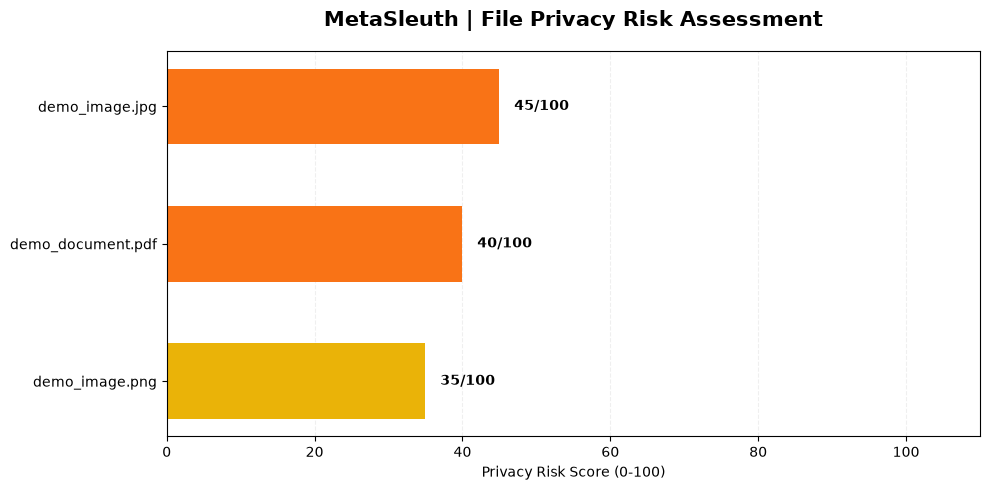

Risk chart saved: privacy_risk_chart.png


In [12]:
# TagRivo - Module 10
# Privacy Risk Score Visualization

import matplotlib.pyplot as plt

chart_df = summary_df.dropna(
    subset=["Risk Score"]
).copy()

if chart_df.empty:

    print("No successful audits available for plotting.")

else:

    chart_df = chart_df.sort_values(
        "Risk Score",
        ascending=True
    )

    risk_colors = {
        "No Detected Risk": "#94A3B8",
        "Low": "#22C55E",
        "Moderate": "#EAB308",
        "High": "#F97316",
        "Critical": "#DC2626"
    }

    colors = [
        risk_colors.get(level, "#64748B")
        for level in chart_df["Risk Level"]
    ]

    fig, ax = plt.subplots(figsize=(10, 5))

    bars = ax.barh(
        chart_df["File Name"],
        chart_df["Risk Score"],
        color=colors,
        height=0.55
    )

    ax.set_title(
        "TagRivo | File Privacy Risk Assessment",
        fontsize=15,
        fontweight="bold",
        pad=18
    )

    ax.set_xlabel("Privacy Risk Score (0-100)")
    ax.set_xlim(0, 110)

    ax.grid(
        axis="x",
        alpha=0.2,
        linestyle="--"
    )

    ax.set_axisbelow(True)

    for bar in bars:

        score = bar.get_width()

        ax.text(
            score + 2,
            bar.get_y() + bar.get_height() / 2,
            f"{score:.0f}/100",
            va="center",
            fontsize=10,
            fontweight="bold"
        )

    plt.tight_layout()

    chart_path = REPORTS_DIR / "privacy_risk_chart.png"

    plt.savefig(
        chart_path,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

    print("Risk chart saved:", chart_path.name)

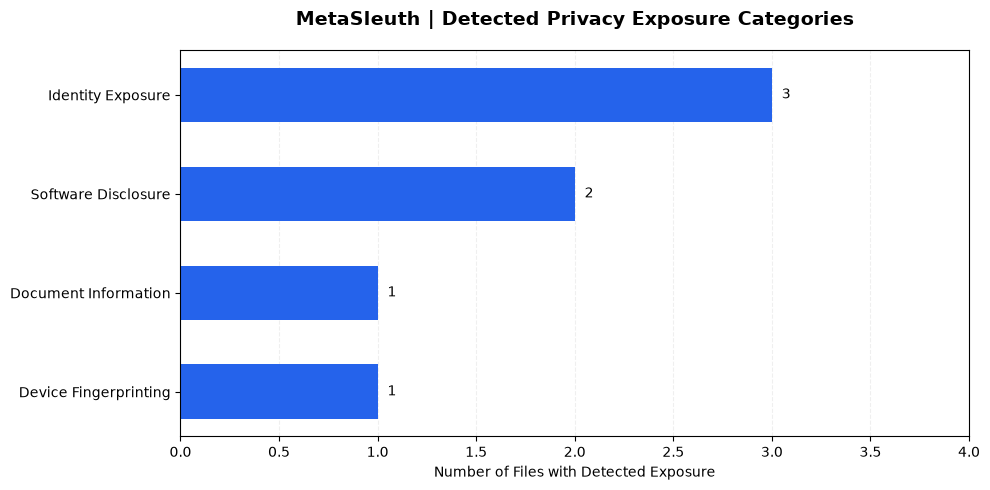

Category chart saved: privacy_category_chart.png


In [13]:
# TagRivo - Module 11
# Privacy Exposure Category Analysis

if findings_df.empty:

    print("No privacy categories available for analysis.")

else:

    category_counts = (
        findings_df["Privacy Category"]
        .value_counts()
        .sort_values(ascending=True)
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    bars = ax.barh(
        category_counts.index,
        category_counts.values,
        color="#2563EB",
        height=0.55
    )

    ax.set_title(
        "TagRivo | Detected Privacy Exposure Categories",
        fontsize=14,
        fontweight="bold",
        pad=18
    )

    ax.set_xlabel("Number of Files with Detected Exposure")

    ax.set_xlim(
        0,
        max(category_counts.values) + 1
    )

    ax.grid(
        axis="x",
        alpha=0.2,
        linestyle="--"
    )

    ax.set_axisbelow(True)

    for bar in bars:

        ax.text(
            bar.get_width() + 0.05,
            bar.get_y() + bar.get_height() / 2,
            str(int(bar.get_width())),
            va="center"
        )

    plt.tight_layout()

    category_chart_path = (
        REPORTS_DIR / "privacy_category_chart.png"
    )

    plt.savefig(
        category_chart_path,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

    print("Category chart saved:", category_chart_path.name)

In [14]:
# TagRivo - Module 12
# Security Report Export Engine

import json
from datetime import datetime, timezone

REPORTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Export file-wise summary
summary_csv_path = (
    REPORTS_DIR / "tagrivo_audit_summary.csv"
)

summary_df.to_csv(
    summary_csv_path,
    index=False
)

# Export detailed privacy findings
findings_csv_path = (
    REPORTS_DIR / "tagrivo_privacy_findings.csv"
)

findings_df.to_csv(
    findings_csv_path,
    index=False
)

# Create a structured JSON report
json_report = {
    "project": "TagRivo",
    "report_type": "Metadata Privacy Security Audit",
    "generated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "dataset": "Synthetic demonstration files",
    "total_files": len(audit_results),
    "successful_audits": sum(
        result["status"] == "Success"
        for result in audit_results
    ),
    "failed_audits": sum(
        result["status"] != "Success"
        for result in audit_results
    ),
    "file_summary": summary_df.to_dict(
        orient="records"
    ),
    "privacy_findings": findings_df.to_dict(
        orient="records"
    ),
    "limitations": (
        "Risk scores describe detected metadata only. "
        "A low or zero score does not guarantee anonymity "
        "or the absence of hidden information."
    )
}

json_report_path = (
    REPORTS_DIR / "tagrivo_security_report.json"
)

with open(
    json_report_path,
    "w",
    encoding="utf-8"
) as report_file:

    json.dump(
        json_report,
        report_file,
        indent=4,
        ensure_ascii=False
    )


print("=" * 60)
print("TAGRIVO | REPORT EXPORT COMPLETED")
print("=" * 60)

print("1. Audit Summary CSV:", summary_csv_path.name)
print("2. Findings CSV:", findings_csv_path.name)
print("3. Security Report JSON:", json_report_path.name)

print("\nAll reporting files saved successfully!")

TAGRIVO | REPORT EXPORT COMPLETED
1. Audit Summary CSV: tagrivo_audit_summary.csv
2. Findings CSV: tagrivo_privacy_findings.csv
3. Security Report JSON: tagrivo_security_report.json

All reporting files saved successfully!


In [15]:
# TagRivo - Module 13
# Reporting Engine Validation Tests

# Test 1: Summary exists
assert not summary_df.empty
print("PASS - Audit summary generated")

# Test 2: All scores are within valid range
valid_scores = summary_df["Risk Score"].dropna()

assert valid_scores.between(0, 100).all()
print("PASS - All risk scores within 0-100")

# Test 3: Required columns exist
required_columns = [
    "File Name",
    "Risk Score",
    "Risk Level",
    "Privacy Findings",
    "Audit Status"
]

assert all(
    column in summary_df.columns
    for column in required_columns
)

print("PASS - Required security fields present")

# Test 4: Summary CSV exists and is readable
assert summary_csv_path.is_file()

loaded_summary = pd.read_csv(summary_csv_path)

assert len(loaded_summary) == len(summary_df)

print("PASS - CSV report verified")

# Test 5: JSON report exists and is valid
assert json_report_path.is_file()

with open(
    json_report_path,
    "r",
    encoding="utf-8"
) as file:

    loaded_json = json.load(file)

assert loaded_json["project"] == "TagRivo"

assert loaded_json["total_files"] == len(audit_results)

print("PASS - JSON report verified")

# Test 6: No raw metadata values in exported JSON
assert "metadata" not in loaded_json

assert all(
    "metadata" not in item
    for item in loaded_json["file_summary"]
)

print("PASS - Raw metadata dictionary not exported")

print("\nAll 6 reporting tests passed!")

PASS - Audit summary generated
PASS - All risk scores within 0-100
PASS - Required security fields present
PASS - CSV report verified
PASS - JSON report verified
PASS - Raw metadata dictionary not exported

All 6 reporting tests passed!


In [16]:
# TagRivo - Module 14
# Secure File Validation Engine

from pathlib import Path
from PIL import Image, ExifTags
import pymupdf
import warnings

# File processing limits
MAX_FILE_BYTES = 20 * 1024 * 1024
MAX_IMAGE_PIXELS = 20_000_000
MAX_PDF_PAGES = 50

SUPPORTED_FILES = {
    ".jpg": "JPEG",
    ".jpeg": "JPEG",
    ".png": "PNG",
    ".pdf": "PDF"
}


def validate_input_file(file_path):

    path = Path(file_path)

    result = {
        "file": path.name,
        "status": "Rejected",
        "file_type": None,
        "reason": ""
    }

    try:

        # Reject symbolic links
        if path.is_symlink():
            result["reason"] = (
                "Symbolic links are not accepted."
            )
            return result

        # Check file existence
        if not path.is_file():
            result["reason"] = (
                "File not found or not a regular file."
            )
            return result

        # Check supported extension
        expected_type = SUPPORTED_FILES.get(
            path.suffix.lower()
        )

        if expected_type is None:
            result["reason"] = (
                "Unsupported file extension."
            )
            return result

        # Check file size
        byte_count = path.stat().st_size

        if byte_count == 0 or byte_count > MAX_FILE_BYTES:
            result["reason"] = (
                "Empty file or exceeds 20 MB limit."
            )
            return result

        # Read magic bytes
        with path.open("rb") as input_file:
            signature = input_file.read(12)

        if signature.startswith(b"\xff\xd8\xff"):
            actual_type = "JPEG"

        elif signature.startswith(
            b"\x89PNG\r\n\x1a\n"
        ):
            actual_type = "PNG"

        elif signature.startswith(b"%PDF-"):
            actual_type = "PDF"

        else:
            actual_type = "Unknown"

        # Detect extension spoofing
        if actual_type != expected_type:
            result["reason"] = (
                "File signature does not match "
                "its extension."
            )
            return result

        # Validate image decoding
        if actual_type in ("JPEG", "PNG"):

            with warnings.catch_warnings():

                warnings.simplefilter(
                    "error",
                    Image.DecompressionBombWarning
                )

                with Image.open(path) as photo:

                    if photo.format != actual_type:
                        raise ValueError(
                            "Image decoder disagrees "
                            "with signature."
                        )

                    width, height = photo.size

                    if (
                        width <= 0
                        or height <= 0
                        or width * height > MAX_IMAGE_PIXELS
                    ):
                        raise ValueError(
                            "Image dimensions exceed "
                            "safety limit."
                        )

                    photo.load()

        # Validate PDF readability
        else:

            with pymupdf.open(path) as document:

                if document.needs_pass:
                    result["reason"] = (
                        "Password-protected PDFs "
                        "are not supported."
                    )
                    return result

                if not (
                    1 <= document.page_count <= MAX_PDF_PAGES
                ):
                    result["reason"] = (
                        "PDF must have 1-50 pages."
                    )
                    return result

                document.load_page(0)

        result.update({
            "status": "Accepted",
            "file_type": actual_type,
            "reason": (
                "Signature and basic parsing "
                "checks passed."
            )
        })

    except Exception as error:

        result["reason"] = (
            "Cannot safely read file "
            f"({type(error).__name__})."
        )

    return result


print("TagRivo Secure File Validator initialized!")

TagRivo Secure File Validator initialized!


In [17]:
# TagRivo - Module 15
# Enhanced EXIF and PDF Metadata Inspector


def _display_value(value, limit=200):

    if isinstance(value, bytes):
        return f"[binary block: {len(value)} bytes]"

    text = str(value).replace("\x00", "")

    if len(text) > limit:
        return text[:limit] + "... [truncated]"

    return text


def _to_decimal_coordinate(
    gps,
    coordinate_id,
    direction_id
):

    parts = gps.get(coordinate_id)

    direction = str(
        gps.get(direction_id, "")
    ).upper()

    allowed = (
        ("N", "S")
        if coordinate_id == 2
        else ("E", "W")
    )

    if (
        direction not in allowed
        or not isinstance(parts, (list, tuple))
        or len(parts) != 3
    ):
        return None

    try:

        degrees, minutes, seconds = (
            float(item) for item in parts
        )

        if (
            degrees < 0
            or not (0 <= minutes < 60)
            or not (0 <= seconds < 60)
        ):
            return None

        coordinate = (
            degrees
            + minutes / 60
            + seconds / 3600
        )

        maximum = (
            90 if coordinate_id == 2 else 180
        )

        if coordinate > maximum:
            return None

        if direction in ("S", "W"):
            coordinate = -coordinate

        return round(coordinate, 6)

    except (
        ValueError,
        TypeError,
        ZeroDivisionError,
        OverflowError
    ):
        return None


def extract_metadata(file_path):

    validation = validate_input_file(file_path)

    if validation["status"] != "Accepted":
        return {"error": validation["reason"]}

    path = Path(file_path)

    metadata = {}

    try:

        if validation["file_type"] in ("JPEG", "PNG"):

            with Image.open(path) as photo:

                metadata["File Type"] = photo.format

                metadata["Dimensions"] = (
                    f"{photo.width} x {photo.height}"
                )

                exif = photo.getexif()

                # Main EXIF directory
                for tag_id, value in exif.items():

                    if tag_id in (34853, 34665):
                        continue

                    tag_name = ExifTags.TAGS.get(
                        tag_id,
                        str(tag_id)
                    )

                    metadata[str(tag_name)] = (
                        _display_value(value)
                    )

                # Nested EXIF directory
                for tag_id, value in (
                    exif.get_ifd(34665).items()
                ):

                    tag_name = ExifTags.TAGS.get(
                        tag_id,
                        str(tag_id)
                    )

                    metadata[str(tag_name)] = (
                        _display_value(value)
                    )

                # GPS information
                gps = exif.get_ifd(34853)

                if gps:

                    metadata["GPSInfo"] = "Present"

                    latitude = _to_decimal_coordinate(
                        gps, 2, 1
                    )

                    longitude = _to_decimal_coordinate(
                        gps, 4, 3
                    )

                    if latitude is not None:
                        metadata["GPSLatitude"] = latitude

                    if longitude is not None:
                        metadata["GPSLongitude"] = longitude

                # PNG text metadata
                if validation["file_type"] == "PNG":

                    for key, value in photo.info.items():

                        if key.lower() not in (
                            "exif",
                            "icc_profile"
                        ):

                            metadata[str(key)] = (
                                _display_value(value)
                            )

        else:

            with pymupdf.open(path) as document:

                for key, value in (
                    document.metadata.items()
                ):

                    if value not in ("", None):

                        metadata[str(key)] = (
                            _display_value(value)
                        )

                metadata["Document Pages"] = (
                    document.page_count
                )

                metadata["XMP Packet Present"] = bool(
                    document.get_xml_metadata()
                )

                metadata["Embedded File Count"] = (
                    document.embfile_count()
                )

    except Exception as error:

        return {
            "error": (
                "Metadata extraction failed "
                f"({type(error).__name__})."
            )
        }

    return metadata


print("Advanced Metadata Inspector initialized!")

Advanced Metadata Inspector initialized!


In [18]:
# TagRivo - Module 16
# Integrated Security Audit Engine


def audit_file(file_path):

    path = Path(file_path)

    metadata = extract_metadata(path)

    if "error" in metadata:

        return {
            "file": path.name,
            "status": "Failed",
            "error": metadata["error"]
        }

    risk_result = calculate_privacy_risk(
        metadata
    )

    return {
        "file": path.name,
        "status": "Success",
        "metadata": metadata,
        "risk_score": risk_result["risk_score"],
        "risk_level": risk_result["risk_level"],
        "findings": risk_result["findings"]
    }


# Run enhanced audits on synthetic samples

sample_names = [
    "demo_image.jpg",
    "demo_image.png",
    "demo_document.pdf"
]

for name in sample_names:

    file_path = SAMPLES_DIR / name

    result = audit_file(file_path)

    print("\n" + "=" * 55)
    print("TAGRIVO SECURITY AUDIT")
    print("=" * 55)

    print("File:", result["file"])
    print("Status:", result["status"])

    if result["status"] == "Success":

        print("Risk Score:", result["risk_score"])
        print("Risk Level:", result["risk_level"])

        print("\nDetected Categories:")

        if not result["findings"]:
            print("No supported risk fields detected.")

        for finding in result["findings"]:

            print(
                "-",
                finding["category"],
                "|",
                finding["points"],
                "points"
            )

        print("\nMetadata Fields Found:")

        for field in result["metadata"]:
            print("-", field)

    else:
        print("Reason:", result["error"])


print("\nEnhanced security audit completed!")


TAGRIVO SECURITY AUDIT
File: demo_image.jpg
Status: Success
Risk Score: 45
Risk Level: High

Detected Categories:
- Identity Exposure | 25 points
- Device Fingerprinting | 20 points

Metadata Fields Found:
- File Type
- Dimensions
- Model
- Artist
- Make

TAGRIVO SECURITY AUDIT
File: demo_image.png
Status: Success
Risk Score: 35
Risk Level: Moderate

Detected Categories:
- Identity Exposure | 25 points
- Software Disclosure | 10 points

Metadata Fields Found:
- File Type
- Dimensions
- Author
- Software

TAGRIVO SECURITY AUDIT
File: demo_document.pdf
Status: Success
Risk Score: 40
Risk Level: High

Detected Categories:
- Identity Exposure | 25 points
- Software Disclosure | 10 points
- Document Information | 5 points

Metadata Fields Found:
- format
- title
- author
- creator
- Document Pages
- XMP Packet Present
- Embedded File Count

Enhanced security audit completed!


In [19]:
# TagRivo - Module 17
# Secure Input Validation Tests

import tempfile
import hashlib

tests_passed = 0


def check_test(name, condition):

    global tests_passed

    assert condition, f"FAILED: {name}"

    tests_passed += 1

    print(f"PASS - {name}")


# Existing sample file checks

for name in [
    "demo_image.jpg",
    "demo_image.png",
    "demo_document.pdf"
]:

    result = validate_input_file(
        SAMPLES_DIR / name
    )

    check_test(
        f"Valid sample: {name}",
        result["status"] == "Accepted"
    )


# Verify the original sample is not modified by a scan

source_file = SAMPLES_DIR / "demo_image.jpg"

before_hash = hashlib.sha256(
    source_file.read_bytes()
).hexdigest()

audit_file(source_file)

after_hash = hashlib.sha256(
    source_file.read_bytes()
).hexdigest()

check_test(
    "Original file unchanged after audit",
    before_hash == after_hash
)


# Generate negative security test inputs

with tempfile.TemporaryDirectory(
    prefix="tagrivo_test_",
    dir=OUTPUT_DIR
) as temporary_folder:

    test_dir = Path(temporary_folder)

    # Unsupported file extension
    unsupported = test_dir / "unsupported.xyz"

    unsupported.write_bytes(b"Test data")

    check_test(
        "Unsupported file rejected",
        validate_input_file(
            unsupported
        )["status"] == "Rejected"
    )

    # Empty file
    empty_file = test_dir / "empty.jpg"

    empty_file.write_bytes(b"")

    check_test(
        "Empty file rejected",
        validate_input_file(
            empty_file
        )["status"] == "Rejected"
    )

    # Extension spoofing
    fake_jpeg = test_dir / "fake_photo.jpg"

    fake_jpeg.write_bytes(
        b"%PDF-1.7\nThis is not a JPEG."
    )

    check_test(
        "Disguised file rejected",
        validate_input_file(
            fake_jpeg
        )["status"] == "Rejected"
    )

    # Corrupted PNG
    damaged_png = test_dir / "damaged.png"

    damaged_png.write_bytes(
        b"\x89PNG\r\n\x1a\ncorrupted"
    )

    check_test(
        "Corrupted PNG rejected",
        validate_input_file(
            damaged_png
        )["status"] == "Rejected"
    )

    # Oversized file
    oversized_file = test_dir / "oversized.jpg"

    with oversized_file.open("wb") as handle:

        handle.seek(MAX_FILE_BYTES)

        handle.write(b"\x00")

    check_test(
        "Oversized file rejected",
        validate_input_file(
            oversized_file
        )["status"] == "Rejected"
    )

    # Encrypted PDF
    locked_pdf = test_dir / "locked.pdf"

    document = pymupdf.open()

    document.new_page()

    document.save(
        str(locked_pdf),
        encryption=pymupdf.PDF_ENCRYPT_AES_256,
        owner_pw="synthetic_owner",
        user_pw="synthetic_user"
    )

    document.close()

    check_test(
        "Encrypted PDF rejected",
        validate_input_file(
            locked_pdf
        )["status"] == "Rejected"
    )

    # Synthetic GPS-enabled JPEG
    gps_file = test_dir / "gps_test.jpg"

    image = Image.new(
        "RGB",
        (24, 24),
        color=(100, 150, 200)
    )

    exif = Image.Exif()

    exif[34853] = {
        1: "N",
        2: (25.0, 30.0, 0.0),
        3: "E",
        4: (72.0, 40.0, 0.0)
    }

    image.save(
        gps_file,
        exif=exif
    )

    gps_metadata = extract_metadata(gps_file)

    check_test(
        "GPS metadata extracted",
        "GPSInfo" in gps_metadata
    )

    check_test(
        "GPS latitude decoded",
        gps_metadata.get("GPSLatitude") == 25.5
    )

    check_test(
        "GPS longitude decoded",
        abs(
            gps_metadata.get("GPSLongitude", 0)
            - 72.666667
        ) < 0.00001
    )

    gps_audit = audit_file(gps_file)

    check_test(
        "GPS privacy risk detected",
        gps_audit.get("risk_score") == 45
    )


print("\n" + "=" * 50)
print("TAGRIVO SECURITY VALIDATION SUMMARY")
print("=" * 50)

print("Tests passed:", tests_passed)
print("Tests failed: 0")

PASS - Valid sample: demo_image.jpg
PASS - Valid sample: demo_image.png
PASS - Valid sample: demo_document.pdf
PASS - Original file unchanged after audit
PASS - Unsupported file rejected
PASS - Empty file rejected
PASS - Disguised file rejected
PASS - Corrupted PNG rejected
PASS - Oversized file rejected
PASS - Encrypted PDF rejected
PASS - GPS metadata extracted
PASS - GPS latitude decoded
PASS - GPS longitude decoded
PASS - GPS privacy risk detected

TAGRIVO SECURITY VALIDATION SUMMARY
Tests passed: 14
Tests failed: 0


In [20]:
# TagRivo - Module 18
# File Integrity and Secure Output Utilities

import hashlib
import uuid
import math

from pathlib import Path
from PIL import Image, ImageOps

# Resource limits for PDF rendering
MAX_PDF_RENDER_PIXELS_PER_PAGE = 8_000_000
MAX_PDF_RENDER_PIXELS_TOTAL = 45_000_000

PDF_RENDER_SCALE = 1.5

# Ensure the sanitized output folder exists
SANITIZED_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def sha256_file(path):

    digest = hashlib.sha256()

    with Path(path).open("rb") as handle:

        for block in iter(
            lambda: handle.read(1024 * 1024),
            b""
        ):
            digest.update(block)

    return digest.hexdigest()


def new_sanitized_path(source):

    extension = Path(source).suffix.lower()

    # Use anonymous output names to avoid
    # copying potentially personal filenames.
    for _ in range(8):

        proposed = SANITIZED_DIR / (
            f"tagrivo_clean_"
            f"{uuid.uuid4().hex[:16]}"
            f"{extension}"
        )

        if not proposed.exists():
            return proposed

    raise FileExistsError(
        "Could not choose an unused output filename."
    )


print("TagRivo Integrity Protection initialized!")

TagRivo Integrity Protection initialized!


In [21]:
# TagRivo - Module 19
# Image Metadata Sanitization Engine


def write_clean_image(source, target):

    with Image.open(source) as opened:

        # Apply EXIF orientation before removing EXIF.
        corrected = ImageOps.exif_transpose(opened)

        try:

            is_png = (
                Path(source).suffix.lower() == ".png"
            )

            alpha_present = (
                "A" in corrected.getbands()
                or "transparency" in opened.info
            )

            if is_png and alpha_present:
                mode = "RGBA"
            else:
                mode = "RGB"

            # Work with decoded pixels, not original
            # metadata-bearing file structures.
            clean_pixels = corrected.convert(mode)

            rebuilt = Image.new(
                mode,
                corrected.size
            )

            rebuilt.paste(clean_pixels)

            # Exclusive file creation prevents
            # accidental overwriting.
            if is_png:

                with Path(target).open("xb") as output_file:

                    rebuilt.save(
                        output_file,
                        format="PNG",
                        optimize=True
                    )

            else:

                with Path(target).open("xb") as output_file:

                    rebuilt.save(
                        output_file,
                        format="JPEG",
                        quality=92,
                        optimize=True
                    )

            clean_pixels.close()
            rebuilt.close()

        finally:
            corrected.close()


print("TagRivo Image Sanitizer initialized!")

TagRivo Image Sanitizer initialized!


In [22]:
# TagRivo - Module 20
# PDF Metadata Sanitization Engine


def write_clean_pdf(source, target):

    with pymupdf.open(source) as original:

        rebuilt = pymupdf.open()

        total_pixels = 0

        try:

            for page in original:

                rect = page.rect

                width = math.ceil(
                    rect.width * PDF_RENDER_SCALE
                )

                height = math.ceil(
                    rect.height * PDF_RENDER_SCALE
                )

                if width <= 0 or height <= 0:
                    raise ValueError(
                        "Invalid PDF page dimensions."
                    )

                pixels = width * height

                total_pixels += pixels

                if (
                    pixels > MAX_PDF_RENDER_PIXELS_PER_PAGE
                    or total_pixels
                    > MAX_PDF_RENDER_PIXELS_TOTAL
                ):
                    raise ValueError(
                        "PDF rendering exceeds "
                        "safe pixel limit."
                    )

                # Render visible page appearance,
                # including supported annotations.
                pixmap = page.get_pixmap(
                    matrix=pymupdf.Matrix(
                        PDF_RENDER_SCALE,
                        PDF_RENDER_SCALE
                    ),
                    colorspace=pymupdf.csRGB,
                    alpha=False,
                    annots=True
                )

                page_jpeg = pixmap.tobytes(
                    "jpeg",
                    jpg_quality=82
                )

                clean_page = rebuilt.new_page(
                    width=rect.width,
                    height=rect.height
                )

                clean_page.insert_image(
                    clean_page.rect,
                    stream=page_jpeg
                )

            # Set blank document metadata.
            rebuilt.set_metadata({})

            pdf_bytes = rebuilt.tobytes(
                garbage=4,
                deflate=True
            )

            if len(pdf_bytes) > MAX_FILE_BYTES:
                raise ValueError(
                    "Sanitized PDF exceeds 20 MB limit."
                )

            # Never overwrite an existing file.
            with Path(target).open("xb") as output_file:
                output_file.write(pdf_bytes)

        finally:
            rebuilt.close()


print("TagRivo PDF Sanitizer initialized!")

TagRivo PDF Sanitizer initialized!


In [23]:
# TagRivo - Module 21
# Automated Sanitization and Verification


def additional_verification(path, file_type):

    problems = []

    if file_type in ("JPEG", "PNG"):

        with Image.open(path) as image:

            if len(image.getexif()) != 0:
                problems.append(
                    "EXIF tags remain in the rebuilt image."
                )

            if file_type == "PNG":

                sensitive_png_keys = {
                    "author",
                    "artist",
                    "software",
                    "comment",
                    "description",
                    "xml:com.adobe.xmp"
                }

                if any(
                    str(key).lower() in sensitive_png_keys
                    for key in image.info
                ):
                    problems.append(
                        "Recognized textual PNG metadata remains."
                    )

    else:

        with pymupdf.open(path) as document:

            if document.get_xml_metadata():
                problems.append(
                    "XMP metadata still exists."
                )

            if document.embfile_count():
                problems.append(
                    "Embedded PDF files still exist."
                )

            fields = (
                "title",
                "author",
                "subject",
                "keywords",
                "creator",
                "producer",
                "creationDate",
                "modDate"
            )

            if any(
                document.metadata.get(key)
                for key in fields
            ):
                problems.append(
                    "A supported PDF document metadata "
                    "field remains."
                )

    return problems


def sanitize_and_verify(file_path):

    source = Path(file_path)

    # Validate original file
    validation = validate_input_file(source)

    if validation["status"] != "Accepted":

        return {
            "file": source.name,
            "status": "Rejected",
            "reason": validation["reason"]
        }

    # Perform baseline audit
    baseline = audit_file(source)

    if baseline["status"] != "Success":

        return {
            "file": source.name,
            "status": "Rejected",
            "reason": baseline["error"]
        }

    original_hash = sha256_file(source)

    destination = new_sanitized_path(source)

    try:

        file_type = validation["file_type"]

        # Generate a new sanitized copy
        if file_type in ("JPEG", "PNG"):

            write_clean_image(
                source,
                destination
            )

        else:

            write_clean_pdf(
                source,
                destination
            )

        # Re-scan generated copy
        after = audit_file(destination)

        if after["status"] != "Success":

            raise RuntimeError(
                "Sanitized output failed validation/rescan: "
                + after["error"]
            )

        # Verify original-file integrity
        original_intact = (
            sha256_file(source) == original_hash
        )

        # Perform additional metadata checks
        problems = additional_verification(
            destination,
            file_type
        )

        if not original_intact:

            problems.append(
                "Source file hash changed during processing."
            )

        if after["findings"]:

            problems.append(
                "Risk categories remain in the sanitized copy."
            )

        is_verified = (
            not problems
            and after["risk_score"] == 0
        )

        if is_verified:
            status = "Verified (supported checks)"
        else:
            status = "Review needed"

        if file_type == "PDF":

            warning = (
                "PDF is image-based: text search, links, "
                "forms, and selectable text may be lost. "
                "Inspect all pages visually."
            )

        else:

            warning = (
                "Image pixels remain visible; metadata "
                "cleanup is not anonymity."
            )

        return {
            "file": source.name,
            "sanitized_file": destination.name,
            "sanitized_path": str(destination),
            "status": status,
            "before_score": baseline["risk_score"],
            "after_score": after["risk_score"],
            "before_categories": [
                item["category"]
                for item in baseline["findings"]
            ],
            "after_categories": [
                item["category"]
                for item in after["findings"]
            ],
            "original_intact": original_intact,
            "issues": problems,
            "warning": warning
        }

    except Exception as error:

        # Remove incomplete output if processing fails.
        destination.unlink(missing_ok=True)

        return {
            "file": source.name,
            "status": "Failed",
            "reason": (
                f"{type(error).__name__}: {error}"
            )
        }


print("TagRivo Verification Engine initialized!")

TagRivo Verification Engine initialized!



TAGRIVO SANITIZATION RESULT
Original: demo_image.jpg
Status: Verified (supported checks)
Before Risk Score: 45
After Risk Score: 0
Original Unchanged: True
Sanitized Copy: tagrivo_clean_b8871cc2c69643f3.jpg

TAGRIVO SANITIZATION RESULT
Original: demo_image.png
Status: Verified (supported checks)
Before Risk Score: 35
After Risk Score: 0
Original Unchanged: True
Sanitized Copy: tagrivo_clean_c61d4845e32541f2.png

TAGRIVO SANITIZATION RESULT
Original: demo_document.pdf
Status: Verified (supported checks)
Before Risk Score: 40
After Risk Score: 0
Original Unchanged: True
Sanitized Copy: tagrivo_clean_7cf80c7bca4842b6.pdf

BEFORE / AFTER SECURITY COMPARISON


,File,Before,After,Risk Reduction,Original Unchanged,Verification Status
0,demo_image.jpg,45,0,45,True,Verified (supported checks)
1,demo_image.png,35,0,35,True,Verified (supported checks)
2,demo_document.pdf,40,0,40,True,Verified (supported checks)


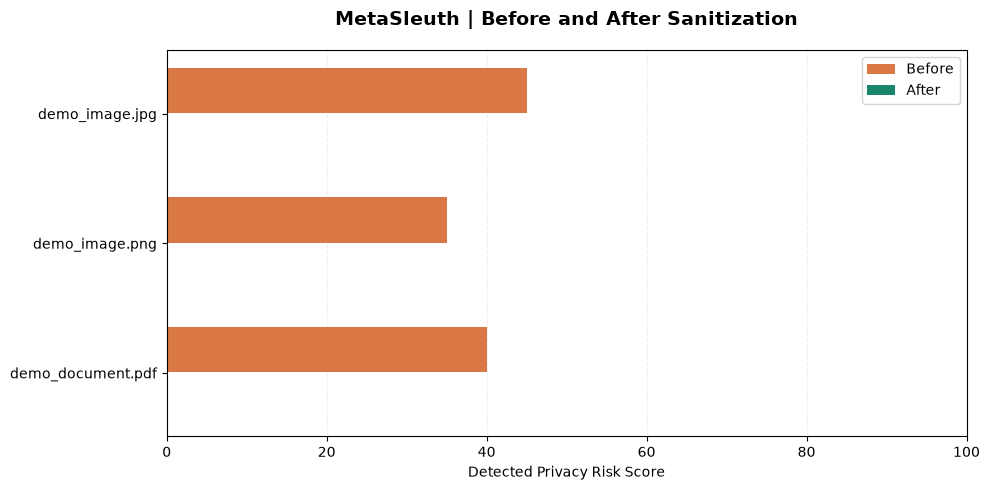


Comparison chart saved successfully.


In [24]:
# TagRivo - Module 22
# End-to-End Sanitization Demonstration

from IPython.display import display

sample_names = [
    "demo_image.jpg",
    "demo_image.png",
    "demo_document.pdf"
]

verified_runs = []

for filename in sample_names:

    result = sanitize_and_verify(
        SAMPLES_DIR / filename
    )

    verified_runs.append(result)

    print("\n" + "=" * 55)
    print("TAGRIVO SANITIZATION RESULT")
    print("=" * 55)

    print("Original:", result["file"])
    print("Status:", result["status"])

    if "after_score" in result:

        print(
            "Before Risk Score:",
            result["before_score"]
        )

        print(
            "After Risk Score:",
            result["after_score"]
        )

        print(
            "Original Unchanged:",
            result["original_intact"]
        )

        print(
            "Sanitized Copy:",
            result["sanitized_file"]
        )

        print("Warning:", result["warning"])

    else:

        print(
            "Reason:",
            result.get("reason")
        )


# Build before-and-after comparison table

comparison_records = []

for result in verified_runs:

    if "after_score" not in result:
        continue

    comparison_records.append({
        "File": result["file"],
        "Before": result["before_score"],
        "After": result["after_score"],
        "Risk Reduction": (
            result["before_score"]
            - result["after_score"]
        ),
        "Original Unchanged": result["original_intact"],
        "Verification Status": result["status"]
    })


comparison_df = pd.DataFrame(
    comparison_records
)

print("\nBEFORE / AFTER SECURITY COMPARISON")

display(comparison_df)


# Save comparison data

comparison_csv_path = (
    REPORTS_DIR / "sanitization_comparison.csv"
)

comparison_df.to_csv(
    comparison_csv_path,
    index=False
)


# Generate comparison visualization

if not comparison_df.empty:

    positions = list(range(len(comparison_df)))

    fig, ax = plt.subplots(figsize=(10, 5))

    before_positions = [
        position - 0.18
        for position in positions
    ]

    after_positions = [
        position + 0.18
        for position in positions
    ]

    ax.barh(
        before_positions,
        comparison_df["Before"],
        height=0.35,
        label="Before",
        color="#D97745"
    )

    ax.barh(
        after_positions,
        comparison_df["After"],
        height=0.35,
        label="After",
        color="#19856B"
    )

    ax.set_yticks(positions)

    ax.set_yticklabels(
        comparison_df["File"]
    )

    ax.set_xlim(0, 100)

    ax.invert_yaxis()

    ax.set_xlabel("Detected Privacy Risk Score")

    ax.set_title(
        "TagRivo | Before and After Sanitization",
        fontsize=14,
        fontweight="bold",
        pad=18
    )

    ax.legend()

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.2
    )

    ax.set_axisbelow(True)

    plt.tight_layout()

    chart_path = (
        REPORTS_DIR / "sanitization_comparison.png"
    )

    plt.savefig(
        chart_path,
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()

    print("\nComparison chart saved successfully.")

In [25]:
# TagRivo - Module 23
# Sanitization Security Test Suite

import tempfile
from PIL import PngImagePlugin

checks = 0


def must_pass(message, condition):

    global checks

    assert condition, f"FAIL - {message}"

    checks += 1

    print("PASS -", message)


# Test normal JPEG, PNG and PDF outputs

for item in verified_runs:

    must_pass(
        f"Verified output: {item['file']}",
        item["status"] == "Verified (supported checks)"
    )

    must_pass(
        f"Original intact: {item['file']}",
        item["original_intact"]
    )

    must_pass(
        f"Risk score zero: {item['file']}",
        item["after_score"] == 0
    )

    must_pass(
        f"Valid output: {item['file']}",
        validate_input_file(
            item["sanitized_path"]
        )["status"] == "Accepted"
    )


# Create temporary synthetic edge-case files

with tempfile.TemporaryDirectory(
    dir=OUTPUT_DIR,
    prefix="tagrivo_step5_"
) as folder:

    tmp = Path(folder)

    # GPS-enabled JPEG
    gps_path = tmp / "gps.jpg"

    gps_image = Image.new(
        "RGB",
        (32, 32),
        (60, 120, 160)
    )

    gps_exif = Image.Exif()

    gps_exif[34853] = {
        1: "N",
        2: (25.0, 30.0, 0.0),
        3: "E",
        4: (72.0, 40.0, 0.0)
    }

    gps_image.save(
        gps_path,
        exif=gps_exif
    )

    gps_before = audit_file(gps_path)

    gps_result = sanitize_and_verify(gps_path)

    must_pass(
        "GPS detected before sanitization",
        any(
            finding["category"] == "Location Exposure"
            for finding in gps_before["findings"]
        )
    )

    must_pass(
        "GPS removed from supported metadata scan",
        (
            gps_result["status"]
            == "Verified (supported checks)"
            and gps_result["after_score"] == 0
        )
    )

    # Transparent PNG with author metadata
    transparent_path = tmp / "transparent.png"

    transparent = Image.new(
        "RGBA",
        (30, 30),
        (30, 80, 120, 0)
    )

    png_metadata = PngImagePlugin.PngInfo()

    png_metadata.add_text(
        "Author",
        "Synthetic Writer"
    )

    transparent.save(
        transparent_path,
        pnginfo=png_metadata
    )

    transparent_result = sanitize_and_verify(
        transparent_path
    )

    with Image.open(
        transparent_result["sanitized_path"]
    ) as clean_png:

        must_pass(
            "PNG transparency preserved",
            clean_png.getpixel((0, 0))[3] == 0
        )

    # Check that sanitized PDF has no text layer
    pdf_result = next(
        item for item in verified_runs
        if item["file"] == "demo_document.pdf"
    )

    with pymupdf.open(
        pdf_result["sanitized_path"]
    ) as clean_pdf:

        must_pass(
            "PDF selectable text removed",
            not clean_pdf[0].get_text().strip()
        )

    # Disguised file rejection
    fake = tmp / "spoofed.jpg"

    fake.write_bytes(
        b"%PDF-1.7\nnot an image"
    )

    must_pass(
        "Disguised file rejected",
        sanitize_and_verify(fake)["status"]
        == "Rejected"
    )


print("\n" + "=" * 55)
print("TAGRIVO SANITIZATION TEST SUMMARY")
print("=" * 55)

print("Tests passed:", checks)
print("Tests failed: 0")

PASS - Verified output: demo_image.jpg
PASS - Original intact: demo_image.jpg
PASS - Risk score zero: demo_image.jpg
PASS - Valid output: demo_image.jpg
PASS - Verified output: demo_image.png
PASS - Original intact: demo_image.png
PASS - Risk score zero: demo_image.png
PASS - Valid output: demo_image.png
PASS - Verified output: demo_document.pdf
PASS - Original intact: demo_document.pdf
PASS - Risk score zero: demo_document.pdf
PASS - Valid output: demo_document.pdf
PASS - GPS detected before sanitization
PASS - GPS removed from supported metadata scan
PASS - PNG transparency preserved
PASS - PDF selectable text removed
PASS - Disguised file rejected

TAGRIVO SANITIZATION TEST SUMMARY
Tests passed: 17
Tests failed: 0


In [ ]:
%pip install flask

In [27]:
import flask
import sys

print("Flask installation successful!")
print("Python executable:", sys.executable)

Flask installation successful!
Python executable: d:\Anaconda\envs\fairflow\python.exe


In [28]:
# TagRivo - Notebook and Website Consistency Test

from tagrivo_core import inspect_upload

sample_files = [
    "demo_image.jpg",
    "demo_image.png",
    "demo_document.pdf"
]

for filename in sample_files:

    path = SAMPLES_DIR / filename

    notebook_result = audit_file(path)

    website_result = inspect_upload(
        path.read_bytes(),
        path.name
    )

    assert notebook_result["status"] == "Success"

    assert (
        notebook_result["risk_score"]
        == website_result["risk_score"]
    ), f"Risk score mismatch: {filename}"

    assert (
        notebook_result["risk_level"]
        == website_result["risk_level"]
    ), f"Risk level mismatch: {filename}"

    print(
        f"PASS - {filename}: "
        f"{website_result['risk_score']}/100"
    )

print("\nTagRivo scoring consistency verified!")

PASS - demo_image.jpg: 45/100
PASS - demo_image.png: 35/100
PASS - demo_document.pdf: 40/100

TagRivo scoring consistency verified!


In [29]:
# TagRivo - Step 6C.6
# Automated Website Integration & Security Tests

from io import BytesIO
import json
import hashlib

from app import app
from tagrivo_core import inspect_upload

test_count = 0


def check(name, condition):
    global test_count

    assert condition, f"FAILED: {name}"

    test_count += 1
    print(f"PASS [{test_count:02d}] - {name}")


test_files = [
    "demo_image.jpg",
    "demo_image.png",
    "demo_document.pdf"
]


with app.test_client() as client:

    for filename in test_files:

        source_path = SAMPLES_DIR / filename
        source_bytes = source_path.read_bytes()

        original_hash = hashlib.sha256(
            source_bytes
        ).hexdigest()

        print(f"\nTesting: {filename}")

        # Submit a real file to sanitization API.
        response = client.post(
            "/api/sanitize",
            data={
                "file": (
                    BytesIO(source_bytes),
                    filename
                )
            },
            content_type="multipart/form-data"
        )

        check(
            "Sanitization API accepted file",
            response.status_code == 200
        )

        result = response.get_json() or {}

        if response.status_code != 200:
            raise AssertionError(result)

        check(
            "Sanitization verification successful",
            result["verification"]["status"]
            == "Verified (supported checks)"
        )

        check(
            "Sanitized risk score is zero",
            result["after"]["risk_score"] == 0
        )

        token = result["token"]

        # Download sanitized copy.
        cleaned_response = client.get(
            f"/api/download/{token}/clean"
        )

        check(
            "Sanitized file download works",
            cleaned_response.status_code == 200
            and len(cleaned_response.data) > 0
        )

        # Independently rescan downloaded bytes.
        clean_filename = (
            "clean.pdf" if filename.endswith(".pdf")
            else "clean.png" if filename.endswith(".png")
            else "clean.jpg"
        )

        rescanned = inspect_upload(
            cleaned_response.data,
            clean_filename
        )

        assert rescanned["risk_score"] == 0

        # Verify original sample is unchanged.
        assert hashlib.sha256(
            source_path.read_bytes()
        ).hexdigest() == original_hash

        # Download and read JSON report.
        json_response = client.get(
            f"/api/download/{token}/json"
        )

        exported_json = json.loads(
            json_response.data.decode("utf-8")
        )

        check(
            "JSON security report valid",
            json_response.status_code == 200
            and exported_json["project"] == "TagRivo"
        )

        # Download and inspect CSV report.
        csv_response = client.get(
            f"/api/download/{token}/csv"
        )

        check(
            "CSV security report valid",
            csv_response.status_code == 200
            and "Risk Score" in csv_response.data.decode(
                "utf-8-sig"
            )
        )

    # Negative test: invalid JPEG.
    invalid = client.post(
        "/api/sanitize",
        data={
            "file": (
                BytesIO(b"not a real image"),
                "fake.jpg"
            )
        },
        content_type="multipart/form-data"
    )

    check(
        "Disguised JPEG rejected",
        invalid.status_code == 400
    )

    # Negative test: empty file.
    empty = client.post(
        "/api/sanitize",
        data={
            "file": (
                BytesIO(b""),
                "empty.png"
            )
        },
        content_type="multipart/form-data"
    )

    check(
        "Empty file rejected",
        empty.status_code == 400
    )

    # Negative test: unknown download token.
    unknown = client.get(
        "/api/download/invalid-token/clean"
    )

    check(
        "Unknown download token rejected",
        unknown.status_code == 404
    )


print("\n" + "=" * 50)
print("TAGRIVO INTEGRATION TEST SUMMARY")
print("=" * 50)

print("Total tests:", test_count)
print("Failed: 0")
print("Integration testing completed successfully!")


Testing: demo_image.jpg
PASS [01] - Sanitization API accepted file
PASS [02] - Sanitization verification successful
PASS [03] - Sanitized risk score is zero
PASS [04] - Sanitized file download works
PASS [05] - JSON security report valid
PASS [06] - CSV security report valid

Testing: demo_image.png
PASS [07] - Sanitization API accepted file
PASS [08] - Sanitization verification successful
PASS [09] - Sanitized risk score is zero
PASS [10] - Sanitized file download works
PASS [11] - JSON security report valid
PASS [12] - CSV security report valid

Testing: demo_document.pdf
PASS [13] - Sanitization API accepted file
PASS [14] - Sanitization verification successful
PASS [15] - Sanitized risk score is zero
PASS [16] - Sanitized file download works
PASS [17] - JSON security report valid
PASS [18] - CSV security report valid
PASS [19] - Disguised JPEG rejected
PASS [20] - Empty file rejected
PASS [21] - Unknown download token rejected

TAGRIVO INTEGRATION TEST SUMMARY
Total tests: 21
Fail

In [1]:
# ============================================================
# TagRivo - Step 6D.4
# Temporary Download Revocation Tests
# ============================================================

from pathlib import Path
from io import BytesIO
import sys

# Set the project path explicitly.
PROJECT_DIR = Path(r"D:\Projects\TagRivo")
SAMPLES_DIR = PROJECT_DIR / "samples"

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

source = SAMPLES_DIR / "demo_image.jpg"

print("Project folder:", PROJECT_DIR)
print("Sample file:", source)
print("Sample exists:", source.is_file())

assert source.is_file(), (
    "demo_image.jpg was not found in the samples folder."
)

# Import updated Flask application.
from app import app

print("\nFlask application imported successfully.")

# Check endpoint registration.
registered_routes = [
    rule.rule for rule in app.url_map.iter_rules()
]

assert "/api/sanitize" in registered_routes, (
    "Sanitization endpoint is missing."
)

assert "/api/discard/<token>" in registered_routes, (
    "Download revocation endpoint is missing."
)

print("Required API routes are registered.\n")

test_count = 0

with app.test_client() as client:

    # TEST 1 - Create sanitized download session.
    response = client.post(
        "/api/sanitize",
        data={
            "file": (
                BytesIO(source.read_bytes()),
                source.name
            )
        },
        content_type="multipart/form-data"
    )

    print("Sanitization HTTP status:", response.status_code)
    print("Sanitization successful:", response.status_code == 200)

    assert response.status_code == 200, (
        "Sanitization failed. Check the response above."
    )

    token = response.get_json()["token"]

    # TEST 2 - Download available before revocation.
    before = client.get(
        f"/api/download/{token}/clean"
    )

    assert before.status_code == 200

    test_count += 1
    print("PASS - Download available before revocation")

    # TEST 3 - Revoke download session.
    revoked = client.post(
        f"/api/discard/{token}"
    )

    assert revoked.status_code == 200, revoked.get_json()

    test_count += 1
    print("PASS - Download session revoked")

    # TEST 4 - Download inaccessible after revocation.
    after = client.get(
        f"/api/download/{token}/clean"
    )

    assert after.status_code == 404

    test_count += 1
    print("PASS - Revoked download inaccessible")

    # TEST 5 - Repeated revocation rejected safely.
    repeated = client.post(
        f"/api/discard/{token}"
    )

    assert repeated.status_code == 404

    test_count += 1
    print("PASS - Repeated revocation safely rejected")


print("\n" + "=" * 50)
print("TAGRIVO DOWNLOAD REVOCATION TEST SUMMARY")
print("=" * 50)
print("Tests passed:", test_count, "/ 4")
print("All 4 revocation tests completed successfully!")

Project folder: D:\Projects\TagRivo
Sample file: D:\Projects\TagRivo\samples\demo_image.jpg
Sample exists: True

Flask application imported successfully.
Required API routes are registered.

Sanitization HTTP status: 200
Sanitization successful: True
PASS - Download available before revocation
PASS - Download session revoked
PASS - Revoked download inaccessible
PASS - Repeated revocation safely rejected

TAGRIVO DOWNLOAD REVOCATION TEST SUMMARY
Tests passed: 4 / 4
All 4 revocation tests completed successfully!
